# **Step 1:** Import Libraries & Setup

In [69]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
    )
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import cross_val_score


RANDOM_STATE = 42 # Make results reproducible and charts consistent
TEST_SIZE = 0.20  # 80/20 split
sns.set_theme(style="whitegrid", palette="Set2")
os.makedirs("images", exist_ok=True)    # charts saved here for the README

def save_fig(name):
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

# **Step 2:** Load & Inspect Dataset

In [70]:
# Load the dataset directly into a Pandas DataFrame
df = sns.load_dataset("iris")

# View the first and last 5 rows
print(df.head())
print("\n")
print(df.tail())
print("\n")

# Check dataset shape, info, and summary statistics
print("Shape of dataset:", df.shape)
print("\n")
df.info()
print("\n")
df.describe()

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


     sepal_length  sepal_width  petal_length  petal_width    species
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica


Shape of dataset: (150, 5)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        ---

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# **Step 3:** Check Data Quality & Clean

In [71]:
# Count missing values and duplicate rows
print("Missing values per column:\n", df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Drop duplicate rows and verify new shape
df = df.drop_duplicates()
print("\nNew shape after dropping duplicates:", df.shape)

# Check class distribution
print("\nClass distribution:")
print(df['species'].value_counts())

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Number of duplicate rows: 1

New shape after dropping duplicates: (149, 5)

Class distribution:
species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


# **Step 4:** Explore Data with Pairplot


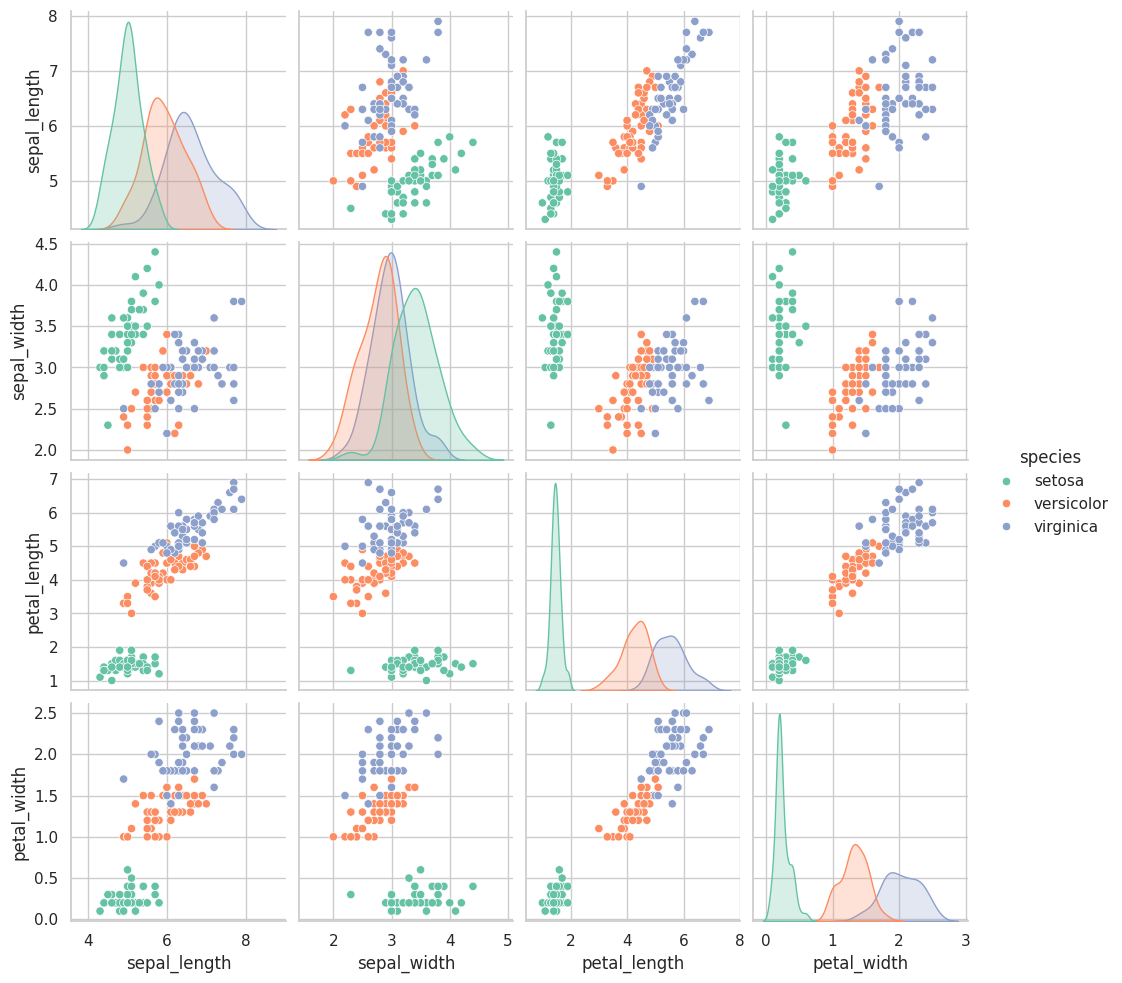

In [72]:
# Generate a pairplot to see multi-feature interactions
sns.pairplot(df, hue='species', palette='Set2')
plt.show()

# **Step 5:** Prepare Data & Build Pipelines



In [73]:
# Separate features (X) and target label (y)
X = df.drop(columns=["species"])
y = df["species"]

# Encode string target labels into integers
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

# Construct leak-proof Pipelines for Logistic Regression and Decision Tree
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42))
])

dt_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', DecisionTreeClassifier(max_depth=3, random_state=42))
])

# Train (fit) both models using the training data
lr_pipeline.fit(X_train, y_train)
dt_pipeline.fit(X_train, y_train)

# Generate predictions on the unseen test set
y_pred_lr = lr_pipeline.predict(X_test)
y_pred_dt = dt_pipeline.predict(X_test)
print("Both models successfully trained and evaluated on the test set!")

X_train shape: (119, 4), X_test shape: (30, 4)
Both models successfully trained and evaluated on the test set!


# **Step 6:** Compare Model Performance

In [74]:
# Helper function to compute core metrics into a dictionary
def compute_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted'),
        'Recall': recall_score(y_true, y_pred, average='weighted'),
        'F1-Score': f1_score(y_true, y_pred, average='weighted')
    }

# Build side-by-side benchmark comparison DataFrame
benchmark_df = pd.DataFrame({
    'Logistic Regression': compute_metrics(y_test, y_pred_lr),
    'Decision Tree': compute_metrics(y_test, y_pred_dt)
})

print("\nSide-by-Side Benchmark Table:")
display(benchmark_df.round(4))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=encoder.classes_))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt, target_names=encoder.classes_))


Side-by-Side Benchmark Table:


,Logistic Regression,Decision Tree
Accuracy,0.9333,0.9667
Precision,0.9333,0.9697
Recall,0.9333,0.9667
F1-Score,0.9333,0.9666



Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# **Step 7:** Plot Confusion Matrices

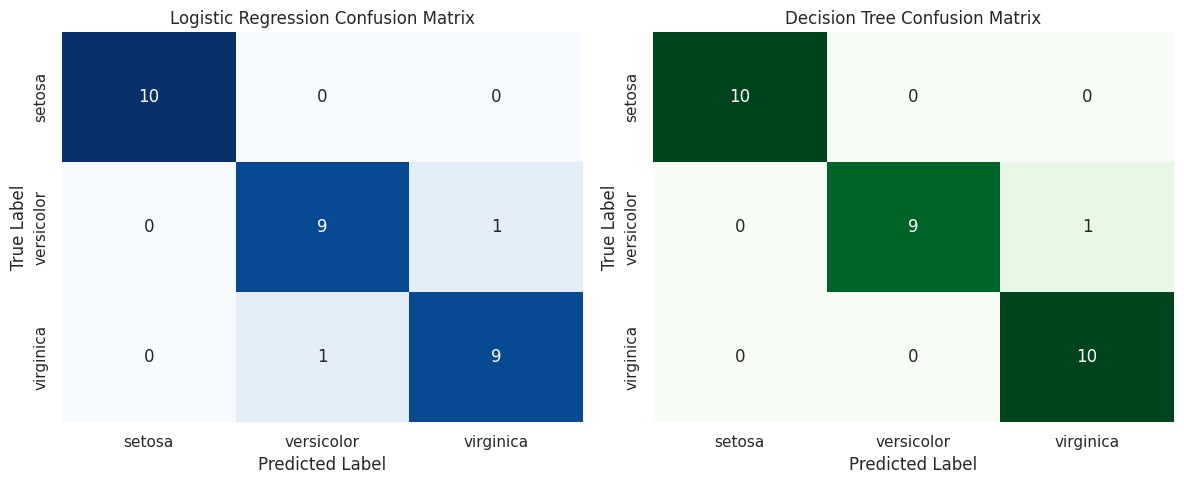

In [75]:
# Plot side-by-side confusion matrix heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred_lr),
    annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=encoder.classes_, yticklabels=encoder.classes_, ax=axes[0]
)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Decision Tree Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred_dt),
    annot=True, fmt='d', cmap='Greens', cbar=False,
    xticklabels=encoder.classes_, yticklabels=encoder.classes_, ax=axes[1]
)
axes[1].set_title('Decision Tree Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
save_fig('confusion_matrices')
plt.show()

# **Step 8:** Visualize Decision Boundaries

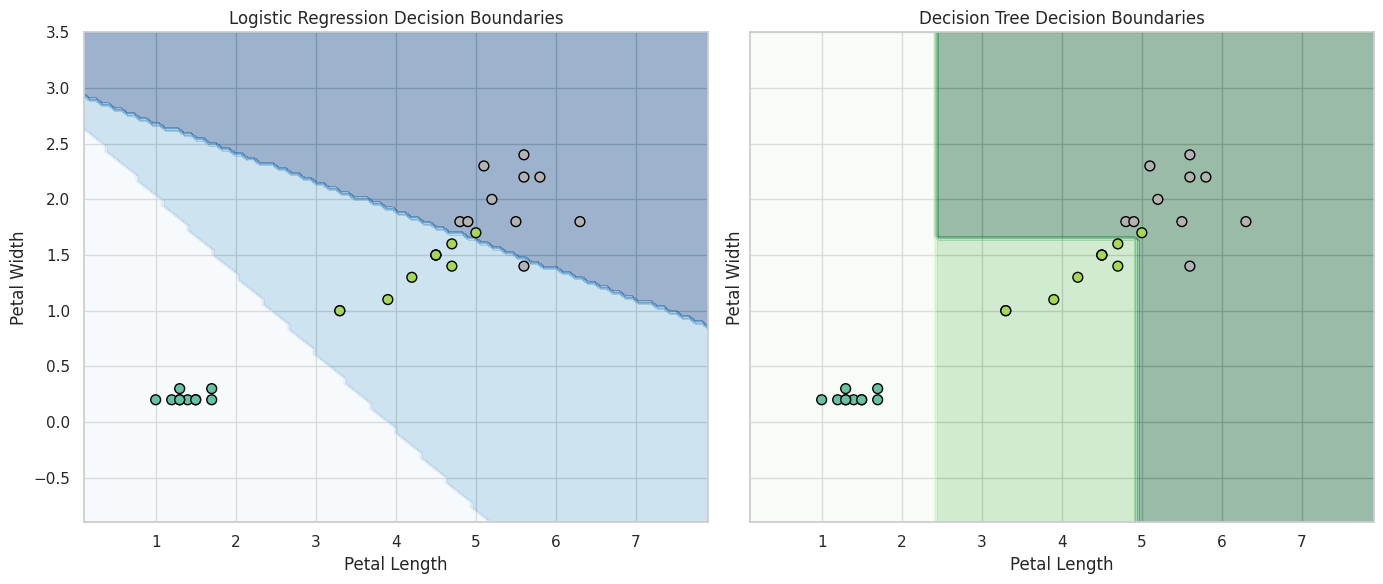

In [76]:
# Use two features (Petal Length and Petal Width) for 2D visualization
feature_indices = [2, 3]
X_train_2d = X_train.values[:, feature_indices]
X_test_2d = X_test.values[:, feature_indices]

# Retrain 2D pipelines for visualization
lr_pipe_2d = Pipeline([('scaler', StandardScaler()), ('classifier', LogisticRegression(random_state=42))])
dt_pipe_2d = Pipeline([('scaler', StandardScaler()), ('classifier', DecisionTreeClassifier(max_depth=3, random_state=42))])

lr_pipe_2d.fit(X_train_2d, y_train)
dt_pipe_2d.fit(X_train_2d, y_train)

# Plot side-by-side decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
models = [
    ('Logistic Regression Decision Boundaries', lr_pipe_2d, 'Blues'),
    ('Decision Tree Decision Boundaries', dt_pipe_2d, 'Greens')
]

for idx, (title, model, cmap_name) in enumerate(models):
    ax = axes[idx]
    DecisionBoundaryDisplay.from_estimator(
        model, X_train_2d, response_method="predict",
        cmap=cmap_name, alpha=0.4, ax=ax,
        xlabel="Petal Length", ylabel="Petal Width"
    )
    ax.scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=y_test, edgecolor="k", cmap=plt.cm.Set2, s=50)
    ax.set_title(title)

plt.tight_layout()
save_fig('decision_boundaries')
plt.show()

# **Step 9:** Cross-Validation Check

In [77]:

# 5-fold cross-validation on full data
lr_cv_scores = cross_val_score(lr_pipeline, X, y_encoded, cv=5, scoring='accuracy')
dt_cv_scores = cross_val_score(dt_pipeline, X, y_encoded, cv=5, scoring='accuracy')

print("--- 5-Fold Cross-Validation Accuracy ---")
print(f"Logistic Regression: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")
print(f"Decision Tree:       {dt_cv_scores.mean():.4f} (+/- {dt_cv_scores.std():.4f})")

--- 5-Fold Cross-Validation Accuracy ---
Logistic Regression: 0.9600 (+/- 0.0389)
Decision Tree:       0.9733 (+/- 0.0249)


# **Step 10:** Check for Overfitting

In [78]:

models_dict = {
    'Logistic Regression': lr_pipeline,
    'Decision Tree': dt_pipeline
}

overfitting_results = []

for name, model in models_dict.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    gap = train_acc - test_acc
    overfitting_results.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Gap (Train - Test)': gap
    })

overfitting_df = pd.DataFrame(overfitting_results)
print("\nOverfitting Analysis:")
display(overfitting_df.round(4))


Overfitting Analysis:


,Model,Train Accuracy,Test Accuracy,Gap (Train - Test)
0,Logistic Regression,0.9580,0.9333,0.0246
1,Decision Tree,0.9832,0.9667,0.0165


# **Step 11:** Make Predictions on New Data

In [79]:
# Format: [sepal_length, sepal_width, petal_length, petal_width]
new_flower = [[5.7, 2.8, 4.1, 1.3]]

# Predict using Logistic Regression
pred_encoded_lr = lr_pipeline.predict(new_flower)
pred_species_lr = encoder.inverse_transform(pred_encoded_lr)[0]

# Predict using Decision Tree
pred_encoded_dt = dt_pipeline.predict(new_flower)
pred_species_dt = encoder.inverse_transform(pred_encoded_dt)[0]

print(f"New Flower Measurements: {new_flower[0]}")
print(f"Logistic Regression Prediction: {pred_species_lr}")
print(f"Decision Tree Prediction:       {pred_species_dt}")

New Flower Measurements: [5.7, 2.8, 4.1, 1.3]
Logistic Regression Prediction: versicolor
Decision Tree Prediction:       versicolor


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
